# Homework 9


**Concepts covered:**

matplotlib, line charts, pie chart, histogram, scatterplot

**Instructions:**

Be sure to run each code block after you edit it to make sure it runs as expected. When you are done, we strongly recommend you run all the code from scratch (Runtime menu -> Restart and Run all) to make sure your current code works for all problems.

If your code raises an exception when run from scratch, it will interfere with the auto-grader process causing you to lose some or all points for this homework. Please ask for help on Piazza, attend office hours or schedule an appointment with your learning facilitator if you get stuck.

**Warning about AI:**

While we encourage you to use AI to generate practice problems, **we recommend against using generative AI in the strongest terms** to solve any part of this assignment. The goal of this assignment is for you to learn these concepts, and while using AI may help you obtain solutions to these problems, you will cheat yourself out of the learning that comes from working through the problems yourself.



**Docstrings and Comments:**

Include a *documentation string* (docstring) for each function definition, as well as comments in the body of your code to explain each control structures (e.g., decision, loop), function call, or formula.


## Shared Imports

Run the cell below to import modules that will be used through out
this homework notebook. Do not import any other modules.
In particular, other charting modules such as Seaborn are not allowed.

In [1]:
# shared imports
import math
import numpy as np
import matplotlib.pyplot as plt


**NOTE: Use the appropriate and optimal ranges for the axis values so that the visualizations are not too small.**


**This homework is partially autograded. The plots will be manually graded so please allow some time for you to get a full score.**

**Problem 1 (review)**

**Concept:** *NumPy arrays, math functions*

**Task:**

Write three functions that generate numerical arrays using NumPy.

Each function takes three parameters:

* **start** – the starting value of the array

* **stop** – the ending value of the array (not inclusive)

* **steps** – the increment between values in the array (the step size used by `np.arange`)

Use `np.arange(start, stop, steps)` to generate the base array of values. Then apply the requested NumPy math function to the entire array.

**Functions to Implement:**

1. `generate_sine_wave(start, stop, steps)`

* Generate a NumPy array of values from `start` to `stop` using `np.arange`.
* Compute the sine of each value using `np.sin`.
* Return the array of sine values.
2. `generate_logs(start, stop, steps)`
* Generate a NumPy array of values from `start` to `stop` using `np.arange`.
* Compute the natural logarithm of each value using `np.log`.
* Return the array of log values.
3. `generate_rounded(start, stop, steps)`
* Generate a NumPy array of values from `start` to `stop` using `np.arange`.
* Round each value using `np.round`.
* Return the rounded array.



In [2]:
def generate_sine_wave(start, stop, steps):
    """Return the sine of each value from start up to, but not including, stop."""
    # np.arange uses steps as the spacing between values, and stop is excluded.
    values = np.arange(start, stop, steps)
    # np.sin computes the sine of every value in the array.
    return np.sin(values)


def generate_logs(start, stop, steps):
    """Return the natural log of each value from start up to, but not including, stop."""
    values = np.arange(start, stop, steps)
    # np.log is the natural logarithm.
    return np.log(values)


def generate_rounded(start, stop, steps):
    """Return each value from start up to, but not including, stop, rounded to the nearest integer."""
    values = np.arange(start, stop, steps)
    # np.round rounds each value to the nearest integer.
    return np.round(values)


**Problem 2 (review)**

**Concept:** *reading CSV file, create an np.array of numbers*

**Task:**

Write a function `read_csv_to_dict(filename)` that reads a CSV file and stores the data in a dictionary.

Your function should:
1. Open the CSV file.
2. Read the first row to obtain column headers.
3. Store each column of data as a NumPy array.
4. Use the column names as keys in the dictionary.
5. Return the dictionary.

Each key should correspond to one column in the CSV file.

Example structure:

```
{
   "open": np.array([...]),
   "close": np.array([...]),
   "volume": np.array([...])
}
```


In [3]:
def read_csv_to_dict(filename):
    """Read a CSV file and return each column as a NumPy array keyed by its header."""
    columns = {}
    # Open the CSV and read it one line at a time.
    with open(filename, "r") as file:
        # The first row holds the column names.
        header = file.readline().strip().split(",")
        for name in header:
            columns[name] = []
        # Each remaining line is one row of data.
        for line in file:
            # Skip blank lines so they are not stored as empty values.
            if line.strip() == "":
                continue
            values = line.strip().split(",")
            # Match each value with the column name in the same position.
            for i in range(len(header)):
                columns[header[i]].append(values[i])

    data = {}
    for name, values in columns.items():
        # Keep a column numeric when every entry converts to float; otherwise keep the text.
        try:
            data[name] = np.array(values, dtype=float)
        except ValueError:
            data[name] = np.array(values)
    return data


**Problem 3**

**Concepts:** *matplotlib, plt line*

**Task:**

Use NumPy and Matplotlib to generate and plot sine and cosine waves.

Complete the following steps:

1. Create a range of values from **0 to 20** using `np.arange`.
2. Compute:
* the sine wave
* the cosine wave

Create four plots:
1. Plot the **sine wave** by itself.
2. Plot the **cosine wave** by itself.
3. Plot **both waves together on the same chart** with a legend.
4. Compute the **ratio of sine to cosine** and plot it.

Each chart should include a **title**, and the combined chart should include a **legend**.


**Plot 1:**

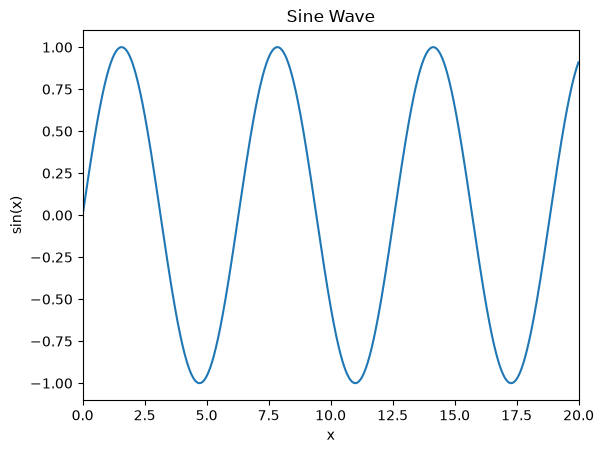

In [4]:
# Values from 0 up to 20. A small step keeps the wave smooth.
x = np.arange(0, 20, 0.01)
sine = generate_sine_wave(0, 20, 0.01)

plt.figure()
plt.plot(x, sine)
plt.title("Sine Wave")
plt.xlabel("x")
plt.ylabel("sin(x)")
# Keep the axes close to the data so the wave fills the chart.
plt.xlim(0, 20)
plt.ylim(-1.1, 1.1)
plt.show()


**Plot 2:**

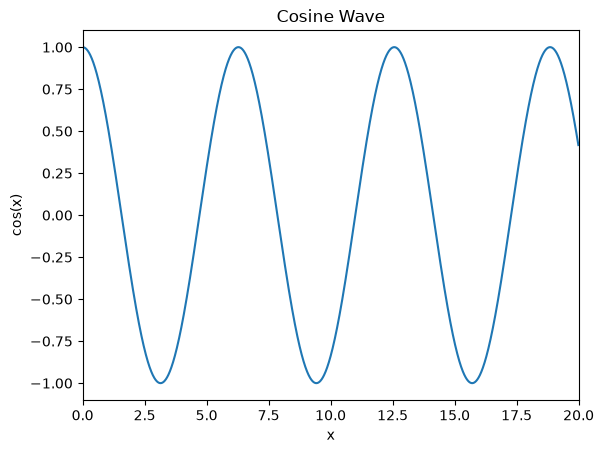

In [5]:
x = np.arange(0, 20, 0.01)
# Cosine of the same x values used for the sine wave.
cosine = np.cos(x)

plt.figure()
plt.plot(x, cosine)
plt.title("Cosine Wave")
plt.xlabel("x")
plt.ylabel("cos(x)")
plt.xlim(0, 20)
plt.ylim(-1.1, 1.1)
plt.show()


**Plot 3:**

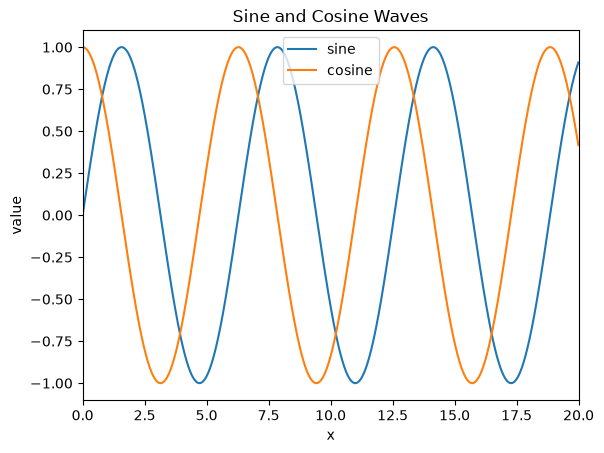

In [6]:
x = np.arange(0, 20, 0.01)
sine = generate_sine_wave(0, 20, 0.01)
cosine = np.cos(x)

plt.figure()
plt.plot(x, sine, label="sine")
plt.plot(x, cosine, label="cosine")
plt.title("Sine and Cosine Waves")
plt.xlabel("x")
plt.ylabel("value")
plt.xlim(0, 20)
plt.ylim(-1.1, 1.1)
# The legend names the two lines on the shared chart.
plt.legend()
plt.show()


**Plot 4:**

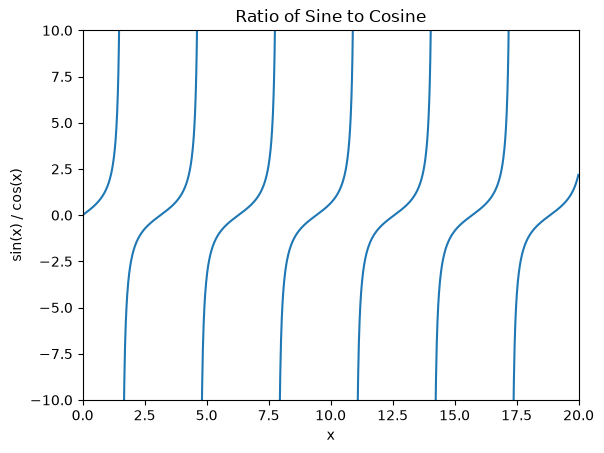

In [7]:
x = np.arange(0, 20, 0.01)
sine = np.sin(x)
cosine = np.cos(x)
# Ratio of sine to cosine. Leave a gap where cosine is near zero, since the ratio is undefined there.
ratio = np.divide(sine, cosine, out=np.full_like(sine, np.nan), where=np.abs(cosine) >= 0.05)

plt.figure()
plt.plot(x, ratio)
plt.title("Ratio of Sine to Cosine")
plt.xlabel("x")
plt.ylabel("sin(x) / cos(x)")
plt.xlim(0, 20)
# A bounded vertical range keeps the repeating ratio visible.
plt.ylim(-10, 10)
plt.show()


**Problem 4**

**Concepts:** *matplotlib, bar chart*

**Task:**

Use the provided lists representing fruit consumption over several days.

Create the following visualizations:

1. A **stacked bar chart** showing strawberry and banana consumption.
2. Two **separate bar charts using subplots**:
* One chart for strawberries (red)
* One chart for bananas (yellow)

Each chart should include:
* a title
* a legend

In [8]:
# STARTER CODE; DO NOT CHANGE
days = range(10)
strawberries = [1, 2, 2, 4, 2, 5, 6, 5, 6, 8]
bananas = [1, 1, 1, 2, 2, 2, 3, 3, 3, 4]


**Plot 1: Stacked Bar Chart**

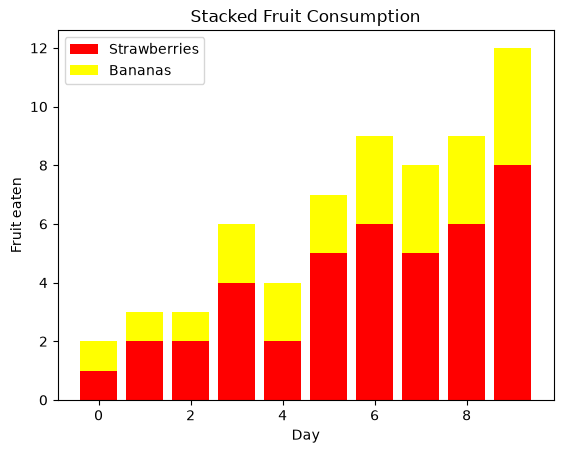

In [9]:
plt.figure()
# Strawberries are the bottom layer of each stacked bar.
plt.bar(days, strawberries, color="red", label="Strawberries")
# Bananas are stacked on top of the strawberry counts.
plt.bar(days, bananas, bottom=strawberries, color="yellow", label="Bananas")
plt.title("Stacked Fruit Consumption")
plt.xlabel("Day")
plt.ylabel("Fruit eaten")
plt.legend()
plt.show()


**Plot 2: Separate Bar Chart**

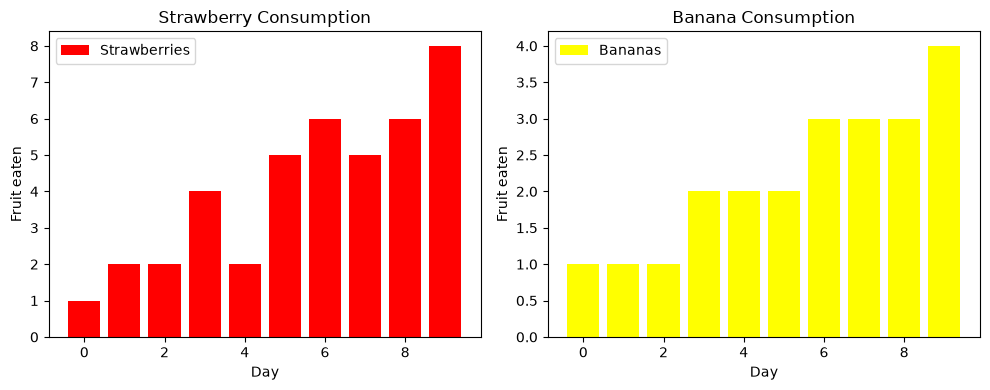

In [10]:
# One row of two subplots: strawberries on the left, bananas on the right.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(days, strawberries, color="red", label="Strawberries")
axes[0].set_title("Strawberry Consumption")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Fruit eaten")
axes[0].legend()

axes[1].bar(days, bananas, color="yellow", label="Bananas")
axes[1].set_title("Banana Consumption")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Fruit eaten")
axes[1].legend()

plt.tight_layout()
plt.show()


**Problem 5**

**Concepts:** *matplotlib, bar chart*

**Task:**

Using the same fruit consumption data from Problem 4, create a **grouped bar chart**.

Your chart should:
1. Display strawberries (red) and bananas (yellow) side-by-side for each day.
2. Use a bar width to offset the second set of bars.
3. Label the x-axis with the day numbers.
4. Include:
    * axis labels
    * a title
    * a legend

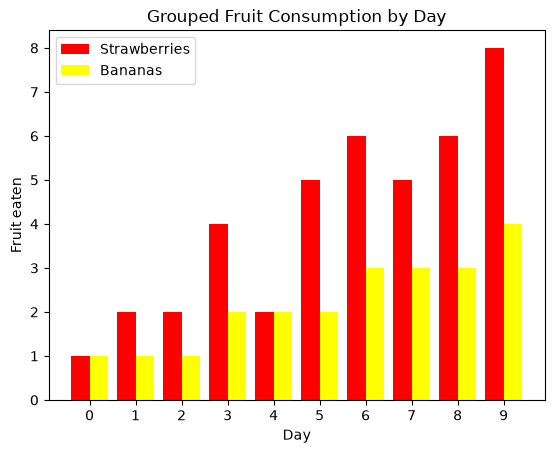

In [11]:
# STARTER CODE; DO NOT CHANGE
days = range(10)
strawberries = [1, 2, 2, 4, 2, 5, 6, 5, 6, 8]
bananas = [1, 1, 1, 2, 2, 2, 3, 3, 3, 4]

# Width of one bar. The second series is shifted by this amount so the bars sit side by side.
bar_width = 0.4
day_numbers = np.arange(len(strawberries))

plt.figure()
# Strawberries sit just to the left of each day number.
plt.bar(day_numbers - bar_width / 2, strawberries, width=bar_width, color="red", label="Strawberries")
# Bananas sit just to the right of each day number.
plt.bar(day_numbers + bar_width / 2, bananas, width=bar_width, color="yellow", label="Bananas")
# Show the day numbers under the grouped bars.
plt.xticks(day_numbers, list(days))
plt.xlabel("Day")
plt.ylabel("Fruit eaten")
plt.title("Grouped Fruit Consumption by Day")
plt.legend()
plt.show()


**Problem 6**

**Concepts:** *matplotlib, scatter plot*


**Task:**

Create a scatter plot that displays the points of a **unit circle**.

Steps:

1. Generate `x` values between **0 and 1**.
2. Compute the corresponding `y` values using the circle equation:

$$y = sqrt(1 − x²)$$

3. Reflect the points across all four quadrants so that the full circle is drawn.
4. Plot the points using `plt.scatter`.

Set the figure size to **(5,5)** so the circle appears correctly proportioned.

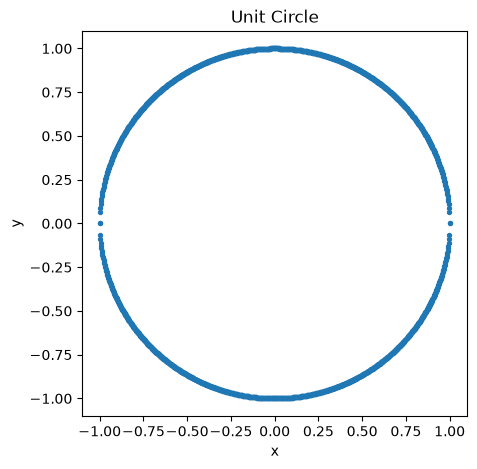

In [12]:
# x values for one quarter of the unit circle, including both 0 and 1.
x = np.linspace(0, 1, 500)
# Upper-right quarter: y = sqrt(1 - x^2).
y = np.sqrt(1 - x ** 2)

# Reflect that quarter across both axes to complete the circle.
x_points = np.concatenate([x, -x, x, -x])
y_points = np.concatenate([y, y, -y, -y])

# A square figure keeps the circle from looking stretched.
plt.figure(figsize=(5, 5))
plt.scatter(x_points, y_points, s=8)
plt.title("Unit Circle")
plt.xlabel("x")
plt.ylabel("y")
plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)
plt.gca().set_aspect("equal", adjustable="box")
plt.show()


**Problem 7**

**Concepts:** *matplotlib, scatter plot*

**Task:**

Create a scatter plot using the provided `x_data` and `y_data`.

Plot the data **four different ways on the same chart**:
1. Original values `(x, y)`
2. Horizontal reflection `(-x, y)`
3. Vertical reflection `(x, -y)`
4. Reflection across both axes `(-x, -y)`

Add:
* a legend
* a chart title

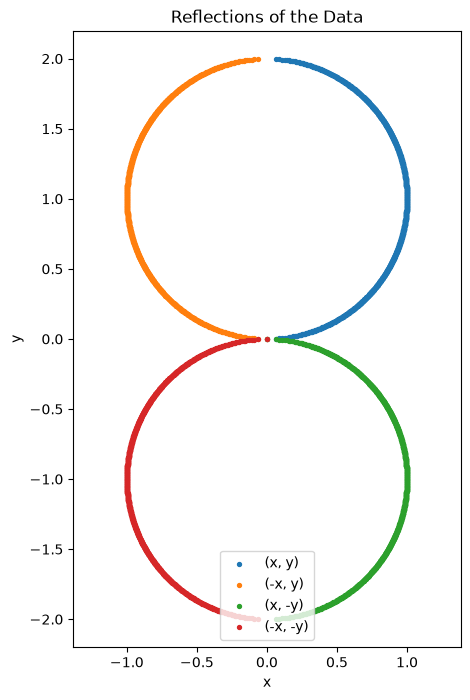

In [13]:
# STARTER CODE; DO NOT CHANGE

y_data = [i / 500 for i in range(1000)]
x_data = [math.sqrt(1 - (y - 1)**2) for y in y_data]


x = np.array(x_data)
y = np.array(y_data)

plt.figure(figsize=(5, 8))
# Original points, then the horizontal, vertical, and diagonal reflections.
plt.scatter(x, y, s=8, label="(x, y)")
plt.scatter(-x, y, s=8, label="(-x, y)")
plt.scatter(x, -y, s=8, label="(x, -y)")
plt.scatter(-x, -y, s=8, label="(-x, -y)")
plt.title("Reflections of the Data")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.axis("equal")
plt.show()


**Problem 8**

**Concepts:** *matplotlib, scatter plot*

**Task:**

Create a scatter plot that produces a **spiral or tornado-like pattern**.

Steps:
1. Generate a list of radius values that gradually increase so the points move farther away from the center over time.
2. Use a sequence of angle values so that each point rotates a little more than the previous one.
3. Compute the x-coordinates by multiplying each radius value by the cosine of its angle.
4. Compute the y-coordinates by multiplying each radius value by the sine of its angle.
5. Use plt.scatter() to plot the (x, y) points.
6. Add a title to the chart.



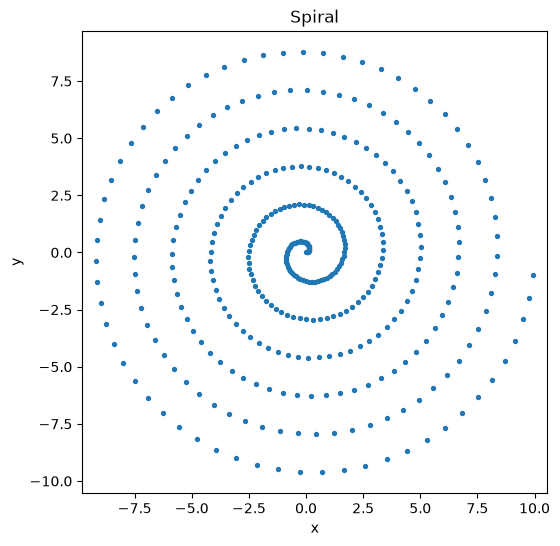

In [14]:
# Each angle turns a little farther than the one before it.
angles = np.arange(0, 12 * np.pi, 0.1)
# The radius grows along with the angle, so the points move outward.
radii = np.linspace(0, 10, len(angles))
# Convert the polar coordinates into x and y.
x = radii * np.cos(angles)
y = radii * np.sin(angles)

plt.figure(figsize=(6, 6))
plt.scatter(x, y, s=8)
plt.title("Spiral")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.show()


**Problem 9**

**Concepts:** *reading CSV file, scatter plot*

**Task:**

Using the helper function `read_csv_to_dict`, read a dataset stored in `p9_data.csv` containing two numerical variables.

The dataset contains the following columns:

* `dataset` (string label)

* `x` (numerical variable)

* `y` (numerical variable)

Create a scatter plot using the **x** and **y** values for the dataset.

Your plot should include:
* x-axis label
* y-axis label
* title

The goal is to visualize how the two variables relate to each other.

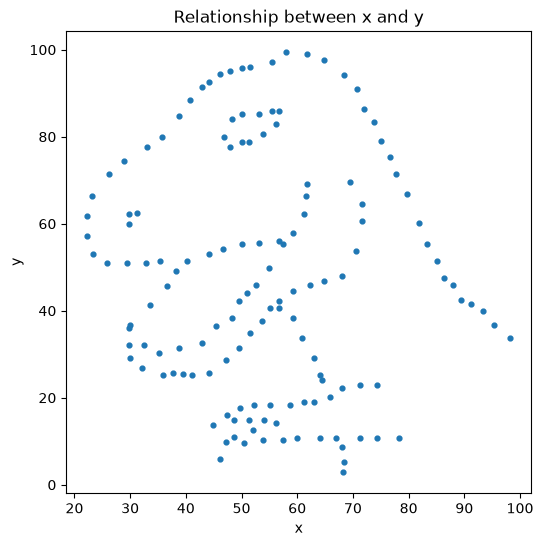

In [15]:
data = read_csv_to_dict("p9_data.csv")
# Use the numeric x and y columns from the file.
x = np.array(data["x"], dtype=float)
y = np.array(data["y"], dtype=float)

plt.figure(figsize=(6, 6))
plt.scatter(x, y, s=12)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Relationship between x and y")
plt.show()


**Problem 10**

**Concepts:** *reading CSV file, line graph*

**Task:**

Write a function:

`create_line_graph(filename, column_name)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Verify the specified column exists.
3. Convert the column values to floats.
4. Plot the values as a **line graph**.

Your graph should include:
* a title
* x-axis labeled **Day Number**
* y-axis labeled with the column name

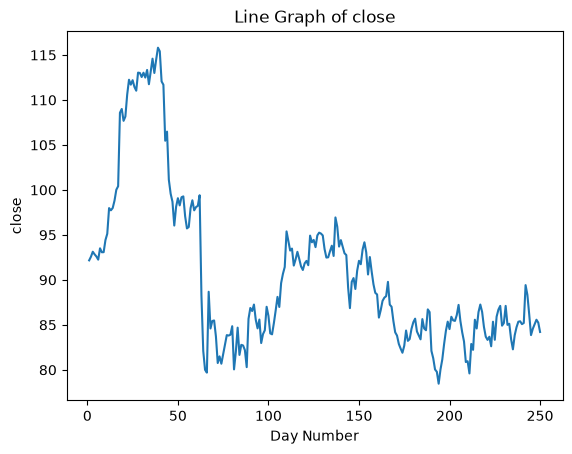

In [16]:
def create_line_graph(filename, column_name):
    """Plot one column from a CSV file as a line graph."""
    data = read_csv_to_dict(filename)
    # Verify that the requested column is present.
    if column_name not in data:
        raise KeyError(f"Column '{column_name}' was not found in {filename}")
    # The line graph needs numeric y values.
    values = np.array(data[column_name], dtype=float)
    # Day numbers follow the row order and start at 1.
    days = np.arange(1, len(values) + 1)

    plt.figure()
    plt.plot(days, values)
    plt.title(f"Line Graph of {column_name}")
    plt.xlabel("Day Number")
    plt.ylabel(column_name)
    plt.show()


# Show the closing prices so the line graph appears in the notebook.
create_line_graph("SBUX.csv", "close")


**Problem 11**

**Concepts:** *reading CSV file, histogram*

**Task:**

Write a function:

`create_histogram(filename, column_name)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Convert the selected column to numeric values.
3. Create a histogram of the data.

Requirements:
* Use **at least 10 bins**.
* Add a title showing the column name.

The histogram should display the distribution of values in the selected column.

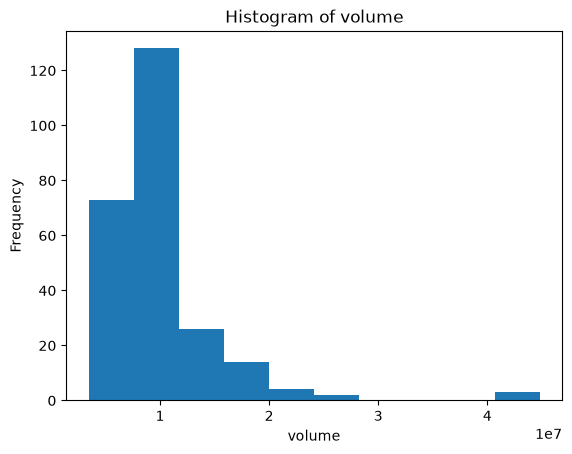

In [17]:
def create_histogram(filename, column_name):
    """Plot a histogram of one numeric column from a CSV file."""
    data = read_csv_to_dict(filename)
    # Convert the selected column to numbers before binning it.
    values = np.array(data[column_name], dtype=float)

    plt.figure()
    # Use 10 bins, which meets the minimum of 10.
    plt.hist(values, bins=10)
    plt.title(f"Histogram of {column_name}")
    plt.xlabel(column_name)
    plt.ylabel("Frequency")
    plt.show()


# Show how trading volume is distributed.
create_histogram("SBUX.csv", "volume")


**Problem 12**

**Concepts:** *reading CSV file, pie chart*

**Task:**

Write a function:

`create_pie_chart(filename, column_name)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Convert the selected column to numeric values.
3. Compute the **mean value** of the column.
4. Determine:
* the percentage of values **greater than the mean**
* the percentage **less than or equal to the mean**

Create a pie chart displaying these two proportions.

Include:
* labels
* percentages
* chart title

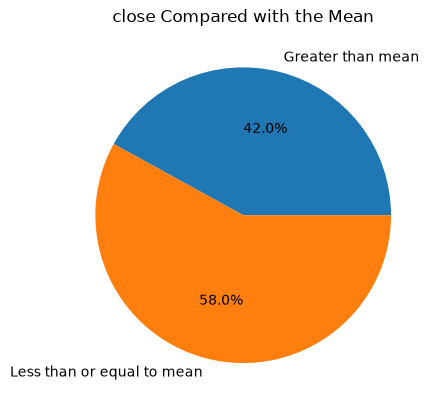

In [18]:
def create_pie_chart(filename, column_name):
    """Plot the share of values above the mean and the share at or below the mean."""
    data = read_csv_to_dict(filename)
    values = np.array(data[column_name], dtype=float)
    # Split the values at the column mean.
    mean_value = np.mean(values)
    greater = np.sum(values > mean_value)
    less_or_equal = np.sum(values <= mean_value)

    plt.figure()
    # autopct prints each wedge as a percentage of the whole column.
    plt.pie(
        [greater, less_or_equal],
        labels=["Greater than mean", "Less than or equal to mean"],
        autopct="%1.1f%%",
    )
    plt.title(f"{column_name} Compared with the Mean")
    plt.show()


# Compare closing prices with their mean.
create_pie_chart("SBUX.csv", "close")


**Problem 13**

**Concepts:** *reading CSV file, scatter plot*

**Task:**

Write a function:

`create_scatter_plot(filename, x_column, y_column)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Extract the specified columns.
3. Convert the values to floats.
4. Create a scatter plot showing the relationship between the two variables.

Include:
* x-axis label
* y-axis label
* title

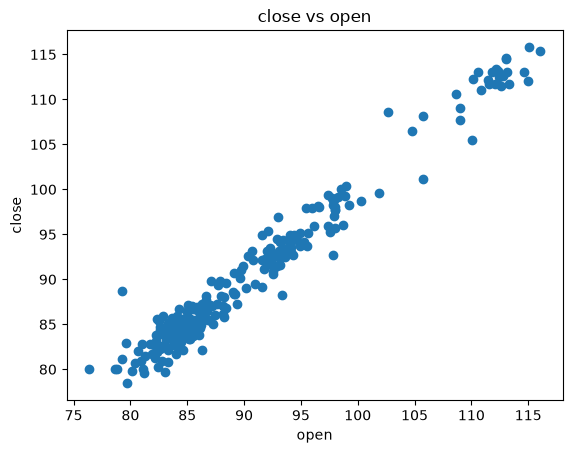

In [19]:
def create_scatter_plot(filename, x_column, y_column):
    """Scatter-plot two numeric columns from a CSV file."""
    data = read_csv_to_dict(filename)
    # Both axes need floating-point coordinates.
    x_values = np.array(data[x_column], dtype=float)
    y_values = np.array(data[y_column], dtype=float)

    plt.figure()
    plt.scatter(x_values, y_values)
    plt.xlabel(x_column)
    plt.ylabel(y_column)
    plt.title(f"{y_column} vs {x_column}")
    plt.show()


# Show how the opening and closing prices move together.
create_scatter_plot("SBUX.csv", "open", "close")
